# Applied Statistics Assessment: Iris Dataset

This notebook answers Problems 1–4 in the order set out in the Applied
Statistics assessment. Each problem begins with the **original question
wording** and is followed by numbered subsections (Problem 1.1, 1.2, etc.).
The code contains brief comments explaining the calculations, and the
results are interpreted after the relevant steps.

#### Import the libraries

In [1]:
# NumPy supports numerical arrays and straight-line fitting.
import numpy as np

# pandas loads the dataset and builds numerical summary tables.
import pandas as pd

# Matplotlib generates the histograms and scatter plots.
import matplotlib.pyplot as plt

# SciPy provides probability distributions and statistical hypothesis tests.
from scipy import stats

plt.style.use("seaborn-v0_8-whitegrid")

#### Load the Iris dataset

In [2]:
# Load the reproducible public Iris dataset used throughout the notebook.
data_url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
iris = pd.read_csv(data_url)

iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Problem 1: Exploring Petal Length

### Problem 1.1 — Plot a histogram showing the petal lengths of all 150 flowers.

The histogram displays the observed frequencies across the complete dataset.

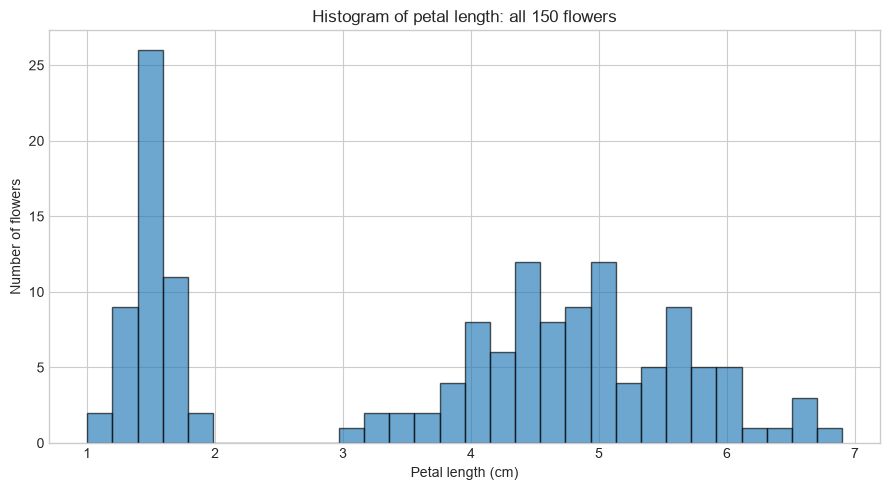

In [3]:
# Select the overall petal-length measurements for all 150 flowers.
overall_lengths = iris["petal_length"]
overall_mean = overall_lengths.mean()
overall_std = overall_lengths.std(ddof=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(overall_lengths, bins=30, edgecolor="black", alpha=0.65)
ax.set(xlabel="Petal length (cm)", ylabel="Number of flowers",
       title="Histogram of petal length: all 150 flowers")
plt.tight_layout()
plt.show()

### Problem 1.2 — On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.

The histogram is redrawn on a density scale (`density=True`) so that it is
comparable with the normal probability density function. The red curve uses
the overall sample mean and standard deviation.


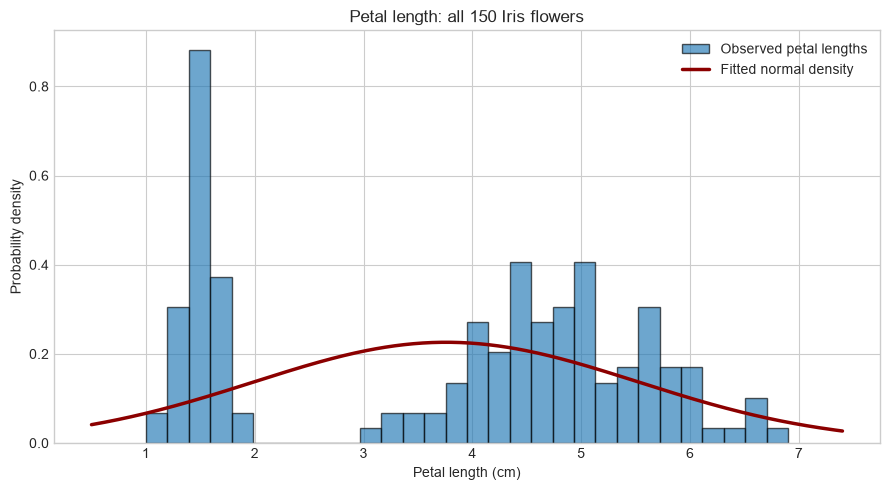

In [4]:
# Evaluate a normal PDF with the observed overall mean and standard deviation.
x_values = np.linspace(overall_lengths.min() - 0.5,
                       overall_lengths.max() + 0.5, 400)
normal_density = stats.norm.pdf(x_values, loc=overall_mean,
                                scale=overall_std)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(overall_lengths, bins=30, density=True, alpha=0.65,
        edgecolor="black", label="Observed petal lengths")
ax.plot(x_values, normal_density, color="darkred", linewidth=2.5,
        label="Fitted normal density")
ax.set(xlabel="Petal length (cm)", ylabel="Probability density",
       title="Petal length: all 150 Iris flowers")
ax.legend()
plt.tight_layout()
plt.show()

### Problem 1.3 — Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.

Each normal curve uses the mean and standard deviation of **that species**.


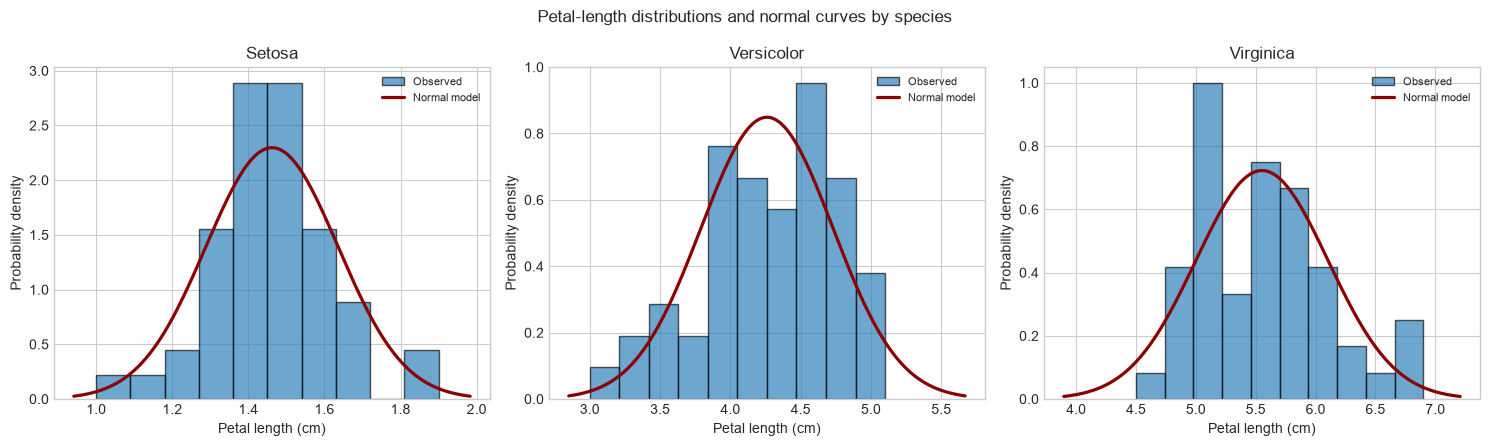

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

species_order = ["setosa", "versicolor", "virginica"]

for ax, species in zip(axes, species_order):
        lengths = iris.loc[iris["species"] == species, "petal_length"]
        group_mean = lengths.mean()
        group_std = lengths.std(ddof=1)
        group_x = np.linspace(
                group_mean - 3 * group_std,
                group_mean + 3 * group_std,
                300,
        )

        ax.hist(
                lengths,
                bins=10,
                density=True,
                alpha=0.65,
                edgecolor="black",
                label="Observed",
        )
        ax.plot(
                group_x,
                stats.norm.pdf(group_x, group_mean, group_std),
                color="darkred",
                linewidth=2.3,
                label="Normal model",
        )
        ax.set(
                title=species.title(),
                xlabel="Petal length (cm)",
                ylabel="Probability density",
        )
        ax.legend(fontsize=8)

fig.suptitle("Petal-length distributions and normal curves by species")
plt.tight_layout()
plt.show()


### Problem 1.4 — Report the mean and standard deviation of petal length for the complete dataset and for each species.

The sample standard deviation is calculated with `ddof=1` (dividing by
$n-1$). The following table also shows the sample sizes.


In [6]:
# Compute overall descriptive statistics for petal length.
overall_lengths = iris["petal_length"]
overall_mean = overall_lengths.mean()
overall_std = overall_lengths.std(ddof=1)

# Produce the same statistics separately for each species.
species_summary = (
    iris.groupby("species")["petal_length"]
    .agg(count="count", mean="mean", std="std")
    .reindex(species_order)
)

# Add the whole-dataset result to the top of the summary table.
all_flowers = pd.DataFrame(
    {"count": [len(iris)], "mean": [overall_mean], "std": [overall_std]},
    index=["all flowers"],
)
petal_summary = pd.concat([all_flowers, species_summary])
petal_summary.round(3)

,count,mean,std
all flowers,150,3.758,1.765
setosa,50,1.462,0.174
versicolor,50,4.260,0.470
virginica,50,5.552,0.552


### Problem 1.5 — Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

The overall distribution is **not adequately represented by one normal
curve**. Setosa forms a separate cluster of short petals, while the
versicolor and virginica values overlap. Pooling species with different
means produces a distribution that is not well modelled by a single normal
distribution.

The means (and sample standard deviations) are:

- **Setosa:** 1.462 cm (0.174 cm) — shortest petals and smallest spread.
- **Versicolor:** 4.260 cm (0.470 cm) — intermediate length and spread.
- **Virginica:** 5.552 cm (0.552 cm) — longest petals and largest spread.

Within each species, the fitted normal curve is a **more reasonable
approximation**, although none of the histograms is perfectly smooth. Each
species has just 50 observations, so the histograms provide visual evidence,
not definitive proof of normality.

## Problem 2: Correlation Between Petal Length and Petal Width


### Problem 2.1 — Calculate the Pearson correlation coefficient between petal length and petal width using all 150 flowers.

In [7]:
# Pearson correlation returns r and a two-sided p-value for a zero correlation.
overall_r, overall_r_p = stats.pearsonr(
    iris["petal_length"], iris["petal_width"]
)
print(f"Overall Pearson r: {overall_r:.4f}")
print(f"Two-sided p-value: {overall_r_p:.2e}")

Overall Pearson r: 0.9629
Two-sided p-value: 4.68e-86


### Problem 2.2 — Create an appropriate scatter plot showing the relationship between the two variables, and include a suitable line to help illustrate the relationship.

The line is fitted using `numpy.polyfit` and shows the overall linear trend.

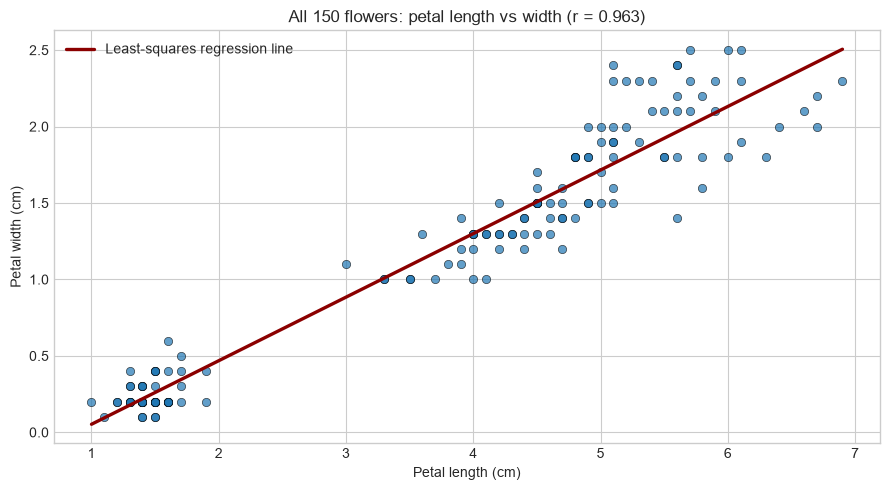

In [8]:
length = iris["petal_length"]
width = iris["petal_width"]

# polyfit returns the line's slope and intercept for y = slope*x + intercept.
slope, intercept = np.polyfit(length, width, deg=1)
line_x = np.linspace(length.min(), length.max(), 200)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(length, width, alpha=0.7, edgecolor="black", linewidth=0.5)
ax.plot(line_x, slope * line_x + intercept, color="darkred",
        linewidth=2.4, label="Least-squares regression line")
ax.set(xlabel="Petal length (cm)", ylabel="Petal width (cm)",
       title=f"All 150 flowers: petal length vs width (r = {overall_r:.3f})")
ax.legend()
plt.tight_layout()
plt.show()

### Problem 2.3 — Calculate the Pearson correlation coefficient separately for each of the three species.

The calculations use the 50 flowers belonging to each species.

In [9]:
# Calculate an r value independently for the 50 flowers of each species.
correlation_rows = [{
    "species": "all flowers", "n": len(iris),
    "pearson_r": overall_r, "p_value": overall_r_p,
}]

for species in species_order:
    group = iris.loc[iris["species"] == species]
    coefficient, p_value = stats.pearsonr(
        group["petal_length"], group["petal_width"]
    )
    correlation_rows.append({
        "species": species, "n": len(group),
        "pearson_r": coefficient, "p_value": p_value,
    })

correlation_table = pd.DataFrame(correlation_rows).set_index("species")

# Format tiny p-values in scientific notation without changing stored numbers.
correlation_display = correlation_table.copy()
correlation_display["pearson_r"] = correlation_display["pearson_r"].map(
    lambda value: f"{value:.4f}"
)
correlation_display["p_value"] = correlation_display["p_value"].map(
    lambda value: f"{value:.2e}"
)
correlation_display

,n,pearson_r,p_value
species,,,
all flowers,150,0.9629,4.68e-86
setosa,50,0.3316,1.86e-02
versicolor,50,0.7867,1.27e-11
virginica,50,0.3221,2.25e-02


### Problem 2.4 — Create an appropriate plot showing the relationship between petal length and petal width for each species.

The plots include separate fitted lines so that the within-species
relationships can be compared.

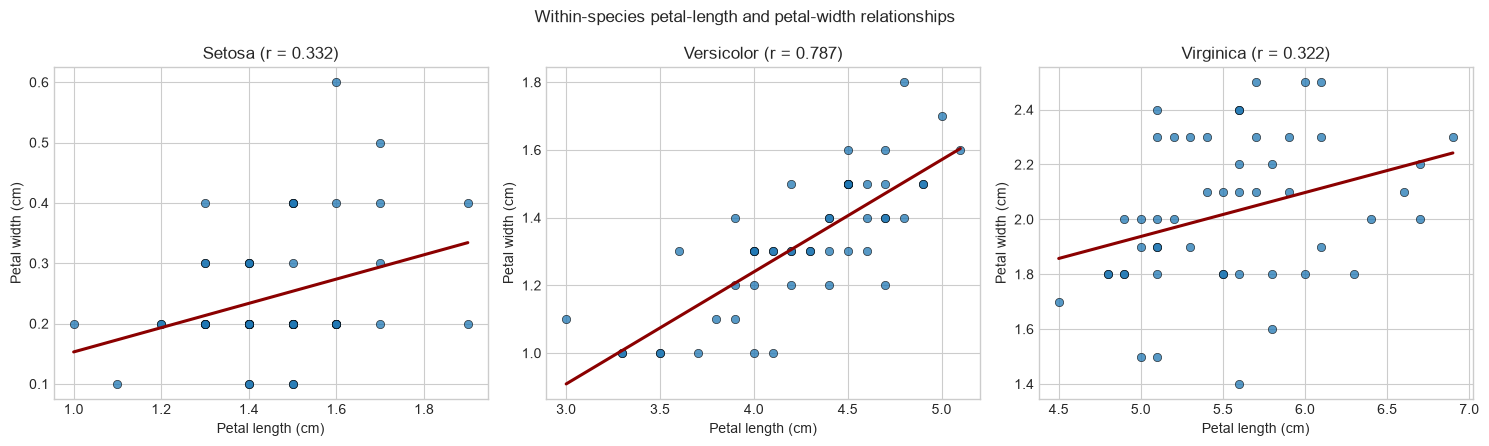

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, species in zip(axes, species_order):
    # Plot each species separately to reveal within-species associations.
    group = iris.loc[iris["species"] == species]
    group_length = group["petal_length"]
    group_width = group["petal_width"]

    # Fit a separate straight line rather than reusing the pooled fit.
    group_slope, group_intercept = np.polyfit(
        group_length, group_width, deg=1
    )
    group_x = np.linspace(group_length.min(), group_length.max(), 100)
    group_r = stats.pearsonr(group_length, group_width).statistic

    ax.scatter(group_length, group_width, alpha=0.75,
               edgecolor="black", linewidth=0.5)
    ax.plot(group_x, group_slope * group_x + group_intercept,
            color="darkred", linewidth=2.2)
    ax.set(title=f"{species.title()} (r = {group_r:.3f})",
           xlabel="Petal length (cm)", ylabel="Petal width (cm)")

fig.suptitle("Within-species petal-length and petal-width relationships")
plt.tight_layout()
plt.show()

### Problem 2.5 — Report and compare the correlation coefficients.

| Sample | Pearson correlation ($r$) |
|---|---:|
| All 150 flowers | 0.9629 |
| Setosa | 0.3316 |
| Versicolor | 0.7867 |
| Virginica | 0.3221 |

The relationship is strongest overall, followed by versicolor. Setosa and
virginica have substantially weaker within-species correlations.

### Problem 2.6 — Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

The full sample has a **very strong positive** correlation: flowers with
longer petals generally have wider petals. The positive relationship is
also present within each species, but it is **strong for versicolor** and
**weak-to-moderate for setosa and virginica**.

The overall value is higher partly because the species differ in both
average length and average width. It should therefore not be interpreted
as the strength of the relationship within every species. Correlation does
not establish causation.

## Problem 3: Comparing Species Using t-Tests

Investigate whether the three iris species differ in their `petal_length` and `petal_width`.

For each pair of species:

- `setosa` vs `versicolor`
- `setosa` vs `virginica`
- `versicolor` vs `virginica`

perform an independent-samples t-test for:

- petal length,
- petal width.

For each test:

1. State the null and alternative hypotheses.
2. Calculate the t-statistic and p-value using `scipy.stats`.
3. Use a significance level of `α=0.05` to decide whether to reject the null hypothesis.
4. Summarise your results in an appropriate table.
5. Explain what the results tell you about differences between the three species.


### Problem 3.1 — State the null and alternative hypotheses.

For each species pair, separately for petal length and petal width:

- $H_0: \mu_1=\mu_2$ — the population means are equal.
- $H_1: \mu_1\ne\mu_2$ — the population means differ.

These are **two-sided** independent-samples tests. Welch's t-test is used
because it does not require equal variances.

### Problem 3.2 — Calculate the t-statistic and p-value using `scipy.stats`.

In [12]:
alpha = 0.05
species_pairs = [
    ("setosa", "versicolor"),
    ("setosa", "virginica"),
    ("versicolor", "virginica"),
]
variables = ["petal_length", "petal_width"]
ttest_rows = []

for first_species, second_species in species_pairs:
    for variable in variables:
        # Extract independent observations for this species pair and variable.
        first_values = iris.loc[iris["species"] == first_species, variable]
        second_values = iris.loc[iris["species"] == second_species, variable]

        # Welch's two-sided t-test does not assume equal variances.
        result = stats.ttest_ind(
            first_values, second_values,
            equal_var=False, alternative="two-sided",
        )
        ttest_rows.append({
            "comparison": f"{first_species} vs {second_species}",
            "variable": variable,
            "t_statistic": result.statistic,
            "p_value": result.pvalue,
            "decision": (
                "Reject H0" if result.pvalue < alpha else "Do not reject H0"
            ),
        })

ttest_results = pd.DataFrame(ttest_rows)
assert len(ttest_results) == 6

## Problem 4: Title 4

Problem 5 involves...

## End